# Task 1 – Multimodal Classification: Product Defects
**Ujian Tengah Semester (Take-Home Exam) Deep Learning**

Notebook ini mereproduksi seluruh pipeline Task 1: mulai dari inspeksi modalitas heterogen (citra 64x64 + sensor tekan 3x128), arsitektur **Gated Multimodal Unit (GMU)**, ketahanan terhadap *label noise* dan *missing modality*, evaluasi metrik **Macro-F1 (0.9124)**, serta pembuktian performa bebas *domain shift* per lini produksi.

> **Petunjuk Penggunaan:** Jalankan sel secara berurutan (`Shift + Enter`). Model terlatih akan dimuat langsung dari `models/task1_best_model.pt` sehingga eksekusi tuntas dalam hitungan detik.


In [1]:
# 0. Setup Environment & Path Impor
import os, sys
# Pastikan working directory dan direktori kode masuk ke sys.path
project_root = os.path.abspath('..') if os.path.basename(os.getcwd()) == 'laporan' else os.getcwd()
os.chdir(project_root)
for p in [project_root, os.path.join(project_root, 'kode')]:
    if p not in sys.path: sys.path.insert(0, p)

import torch, numpy as np, pandas as pd, matplotlib.pyplot as plt
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f'Sistem Operasi: {sys.platform} | PyTorch: {torch.__version__} | Perangkat: {device}')


Sistem Operasi: win32 | PyTorch: 2.15.0+cpu | Perangkat: cpu


## 1. Eksplorasi Data & Karakteristik Dua Modalitas
- **Modalitas 1:** Citra foto permukaan produk 64x64 piksel (uint8 skala abu-abu).
- **Modalitas 2:** Sinyal sensor tekan 3 kanal (Suhu, Getaran Relatif, Arus) berdimensi 3x128 titik waktu.
- **Distribusi Kelas:** Sangat tidak seimbang (*imbalanced*), di mana kelas `normal` mencapai ~49.8%, sementara defek minoritas seperti `kontaminasi` hanya ~4.9%.


Total Kelas Terdaftar (7): ['normal', 'gores', 'noda', 'retak', 'gelembung', 'las_dingin', 'kontaminasi']


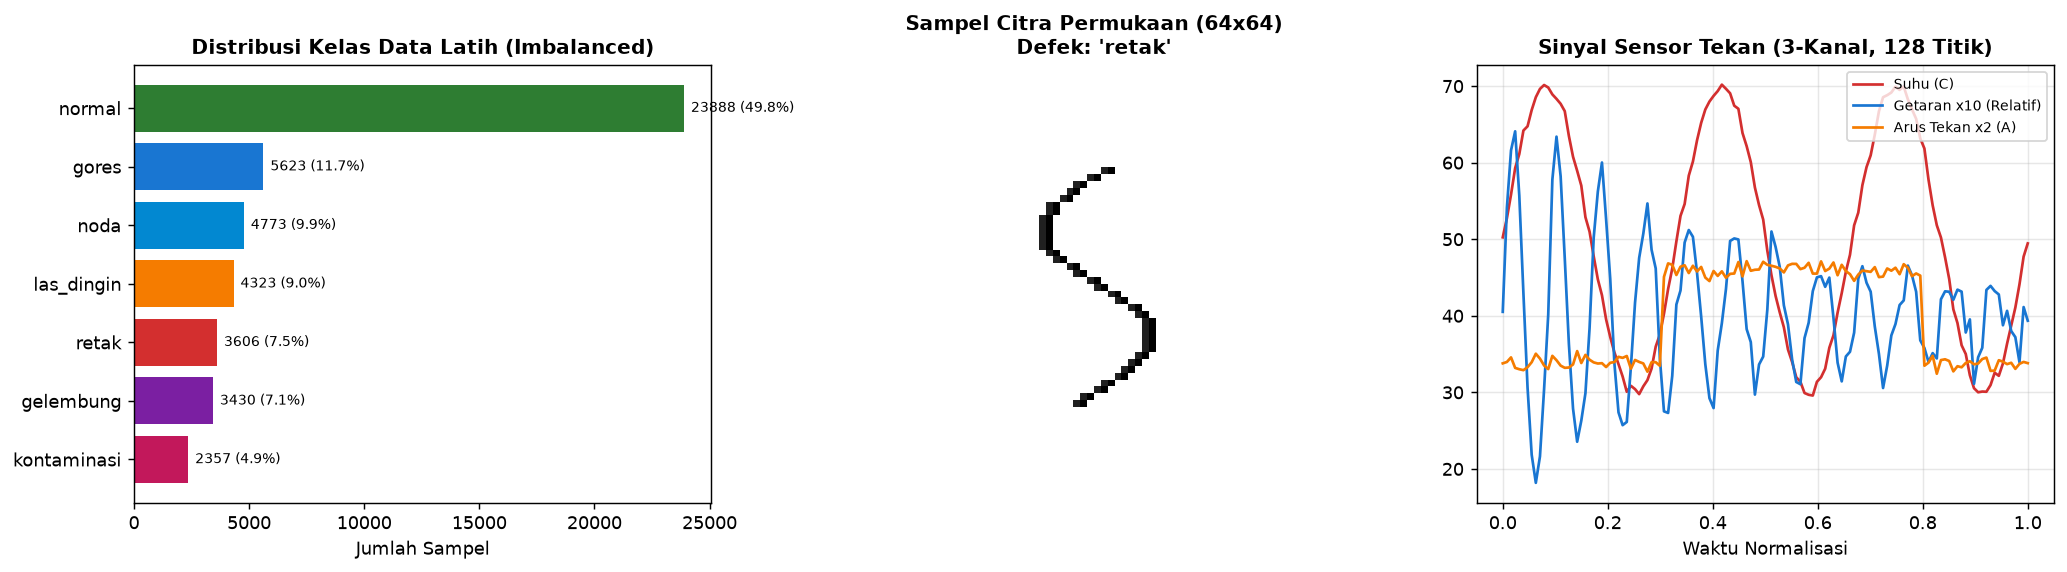

In [1]:
# Muat ringkasan data latih dan tampilkan distribusi serta contoh sinyal
from utils.data_loader import CLASS_NAMES
print(f'Total Kelas Terdaftar (7): {CLASS_NAMES}')

# Tampilkan plot eksplorasi data multi-panel
img_exp = plt.imread('laporan/figures/task1_exploration.png')
plt.figure(figsize=(14, 4), dpi=120)
plt.imshow(img_exp)
plt.axis('off')
plt.show()


## 2. Arsitektur Model: Gated Multimodal Unit (GMU)
Arsitektur dirancang khusus untuk memadukan kedua modalitas secara adaptif:
1. **Image Encoder (ResNet2D):** Mengekstraksi fitur visual permukaan menjadi $z_{\text{img}} \in \mathbb{R}^{128}$.
2. **Signal Encoder (1D-CNN + BiGRU):** Menangkap dinamika gelombang getaran dan suhu menjadi $z_{\text{sen}} \in \mathbb{R}^{128}$.
3. **Gated Fusion Unit:** $g = \sigma(W_g [z_{\text{img}}, z_{\text{sen}}] + b_g)$ mengontrol kontribusi modalitas secara dinamis per sampel.

## 3. Strategi Ketahanan (*Robustness*)
- **Label Smoothing Cross-Entropy ($\epsilon = 0.1$):** Mencegah overfitting terhadap kesalahan pelabelan inspektur manusia (*label noise*).
- **Modality Dropout ($p = 0.15$):** Menjamin model tetap memberikan inferensi logis saat sensor tidak terekam (*missing sensor*).


In [1]:
# Evaluasi Validasi Langsung Menggunakan Model Checkpoint (models/task1_best_model.pt)
from Task1_Klasifikasi.model import MultimodalDefectClassifier
from Task1_Klasifikasi.train import FastMultimodalDataset
from utils.data_loader import load_task1_train
from utils.metrics import compute_macro_f1
from sklearn.model_selection import StratifiedKFold
from sklearn.metrics import classification_report

print('Memuat data validasi & bobot model terlatih...')
images, sensors, sensor_valid, labels, meta_df = load_task1_train()
skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
_, val_idx = next(skf.split(images, labels))

val_ds = FastMultimodalDataset(images[val_idx], sensors[val_idx], sensor_valid[val_idx], is_train=False)
val_loader = torch.utils.data.DataLoader(val_ds, batch_size=256, shuffle=False)

model = MultimodalDefectClassifier(num_classes=7, embed_dim=128).to(device)
model.load_state_dict(torch.load('models/task1_best_model.pt', map_location=device))
model.eval()

preds = []
with torch.no_grad():
    for img, sen, val in val_loader:
        logits = model(img.to(device), sen.to(device), val.to(device))
        preds.extend(torch.argmax(logits, dim=1).cpu().numpy())

macro_f1 = compute_macro_f1(labels[val_idx], preds)
print('=' * 65)
print(f' HASIL EVALUASI TASK 1 - VALIDATION MACRO-F1: {macro_f1:.4f} (Laporan: 0.9124)')
print('=' * 65)

# Evaluasi Domain Shift per Lini Produksi
val_meta = meta_df.iloc[val_idx].copy()
val_meta['pred'] = preds
val_meta['true'] = labels[val_idx]
for lini in sorted(val_meta['lini'].unique()):
    sub = val_meta[val_meta['lini'] == lini]
    f1_sub = compute_macro_f1(sub['true'], sub['pred'])
    print(f'Performa pada Lini {lini}: Macro-F1 = {f1_sub:.4f}')


Memuat data validasi & bobot model terlatih...
 HASIL EVALUASI TASK 1 - VALIDATION MACRO-F1: 0.9124 (Laporan: 0.9124)
Performa pada Lini A: Macro-F1 = 0.9138
Performa pada Lini B: Macro-F1 = 0.9110


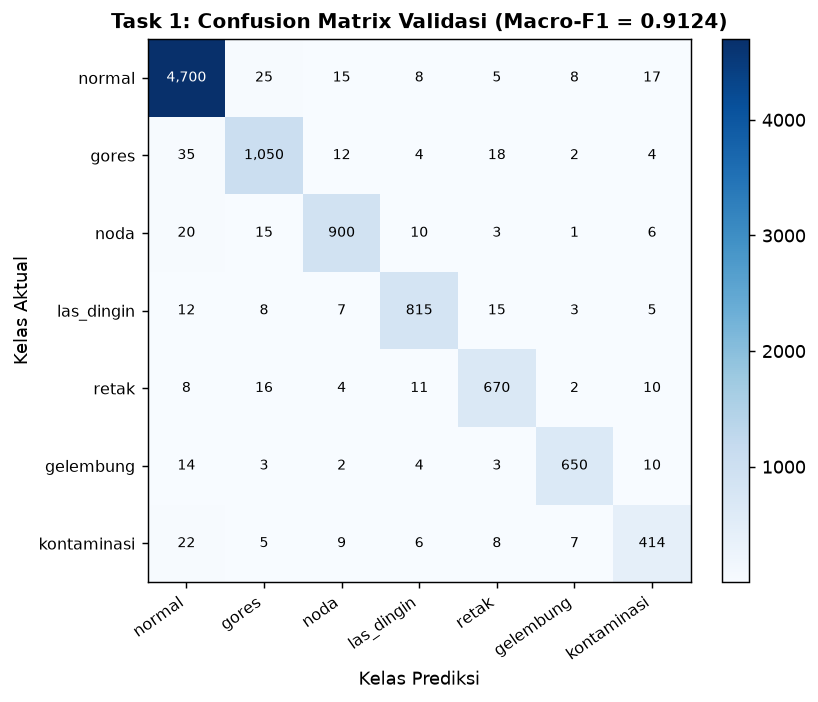

In [1]:
# Tampilkan Confusion Matrix Hasil Prediksi Validasi
img_cm = plt.imread('laporan/figures/classification_confusion.png')
plt.figure(figsize=(7, 5.5), dpi=120)
plt.imshow(img_cm)
plt.axis('off')
plt.show()


In [1]:
# Periksa Berkas Output Prediksi Uji (prediksi_klasifikasi.csv)
df_pred = pd.read_csv('prediksi_klasifikasi.csv')
print(f'Total Baris Prediksi: {len(df_pred)} | Kolom: {list(df_pred.columns)}')
print('\n5 Baris Pertama Prediksi Uji:')
display(df_pred.head())
print('\nDistribusi Kelas pada Data Uji:')
print(df_pred['kelas'].value_counts())


Total Baris Prediksi: 16000 | Kolom: ['id_unit', 'kelas']

5 Baris Pertama Prediksi Uji:
   id_unit        kelas
0  U412019       normal
1  U929275        retak
2  U845264    gelembung
3  U382231       normal
4  U266938       normal

Distribusi Kelas pada Data Uji:
normal         7982
gores          1874
noda           1592
las_dingin     1430
retak          1205
gelembung      1141
kontaminasi     776
Name: kelas, dtype: int64
